# 09: Evaluate the measured hexes

In [1]:
import spatialdata as sd
import spatialdata_plot
from pathlib import Path
import matplotlib.pyplot as plt
from spatialdata.models import TableModel
import numpy as np
import seaborn as sns
import anndata as ad
import scanpy as sc
import scanpy.external as sce
import pandas as pd

import pycytominer
from pycytominer.operations import RobustMAD

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [3]:
# sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_hexes_measured.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_hexes300_measured.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


In [5]:
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes_measured.zarr
├── Images
│     ├── 'hne_baked': DataTree[cyx] (3, 52833, 47441), (3, 26416, 23720), (3, 13207, 11860), (3, 6604, 5930)
│     ├── 'morphology_focus': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
│     └── 'morphology_mip': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'cell_labels_subset': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'filtered_hexes': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     └── 'nucleus_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (330

In [4]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes300_measured.zarr
├── Images
│     └── 'hne_baked': DataTree[cyx] (3, 41411, 45749), (3, 20705, 22874), (3, 10352, 11437), (3, 5175, 5718)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'filtered_hexes': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
└── Tables
      ├── 'morphology': AnnData (22437, 957)
      └── 'table': AnnData (365604, 380)
with coordinate systems:
    ▸ 'global', with elements:
        hne_baked (Images), cell_labels (Labels), filtered_hexes (Labels)

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


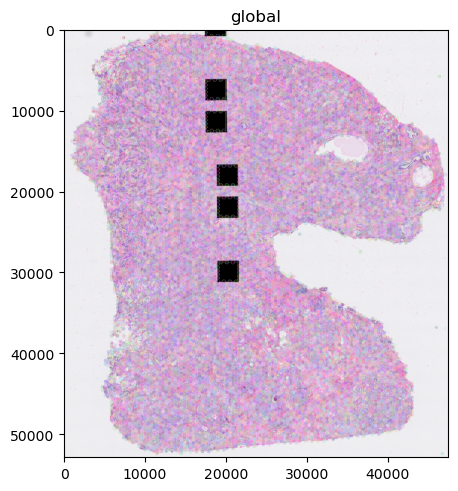

In [7]:
(
    sdata_sample1
    .pl.render_images("hne_baked")
    .pl.render_labels("filtered_hexes", fill_alpha=0.1, outline_alpha=1)
    .pl.show()
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


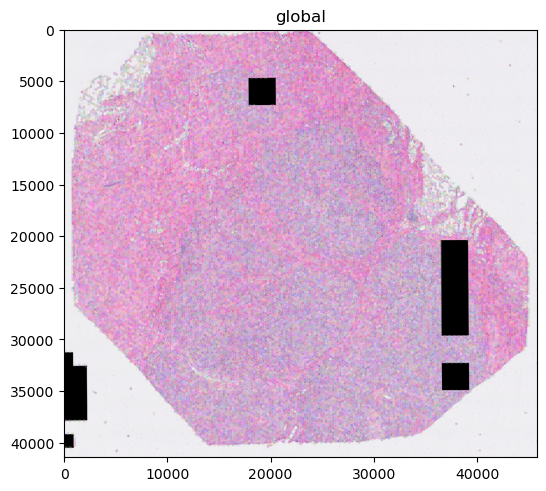

In [5]:
(
    sdata_sample2
    .pl.render_images("hne_baked")
    .pl.render_labels("filtered_hexes", fill_alpha=0.1, outline_alpha=1)
    .pl.show()
)

## PyCytoMiner


### Combine adatas into one

In [5]:
# sdata_sample1.tables["morphology"].obs["sample"] = "sample1"
sdata_sample2.tables["morphology"].obs["sample"] = "sample2"

In [6]:
# how many duplicate obs_names?
# print(sdata_sample1.tables["morphology"].obs_names.duplicated().sum(), "dup obs in sample1")
print(sdata_sample2.tables["morphology"].obs_names.duplicated().sum(), "dup obs in sample2")

# how many duplicate var_names?
# print(sdata_sample1.tables["morphology"].var_names.duplicated().sum(), "dup var in sample1")
print(sdata_sample2.tables["morphology"].var_names.duplicated().sum(), "dup var in sample2")


0 dup obs in sample2
12 dup var in sample2


In [7]:
# sdata_sample1.tables["morphology"].var_names_make_unique()
sdata_sample2.tables["morphology"].var_names_make_unique()

In [8]:
# sdata_sample1.tables["morphology"].obs_names = [
#     f"{'s1' if sample == 'sample1' else 's2'}-{old_name}"
#     for old_name, sample in zip(sdata_sample1.tables["morphology"].obs.index, sdata_sample1.tables["morphology"].obs["sample"])
# ]
sdata_sample2.tables["morphology"].obs_names = [
    f"{'s1' if sample == 'sample1' else 's2'}-{old_name}"
    for old_name, sample in zip(sdata_sample2.tables["morphology"].obs.index, sdata_sample2.tables["morphology"].obs["sample"])
]

# adata_morphology_raw = ad.concat([sdata_sample1.tables["morphology"], sdata_sample2.tables["morphology"]], axis=0)
adata_morphology_raw = sdata_sample2.tables["morphology"]

In [10]:
adata_morphology_raw

AnnData object with n_obs × n_vars = 22437 × 957
    obs: 'region', 'label_id', 'sample'
    uns: 'spatialdata_attrs'

### First look

In [12]:
# we expect this to be bad

sc.pp.neighbors(adata_morphology_raw)
sc.tl.umap(adata_morphology_raw)
sc.tl.leiden(adata_morphology_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 957 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/tmp/ipykernel_4074207/2548107697.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_morphology_raw)


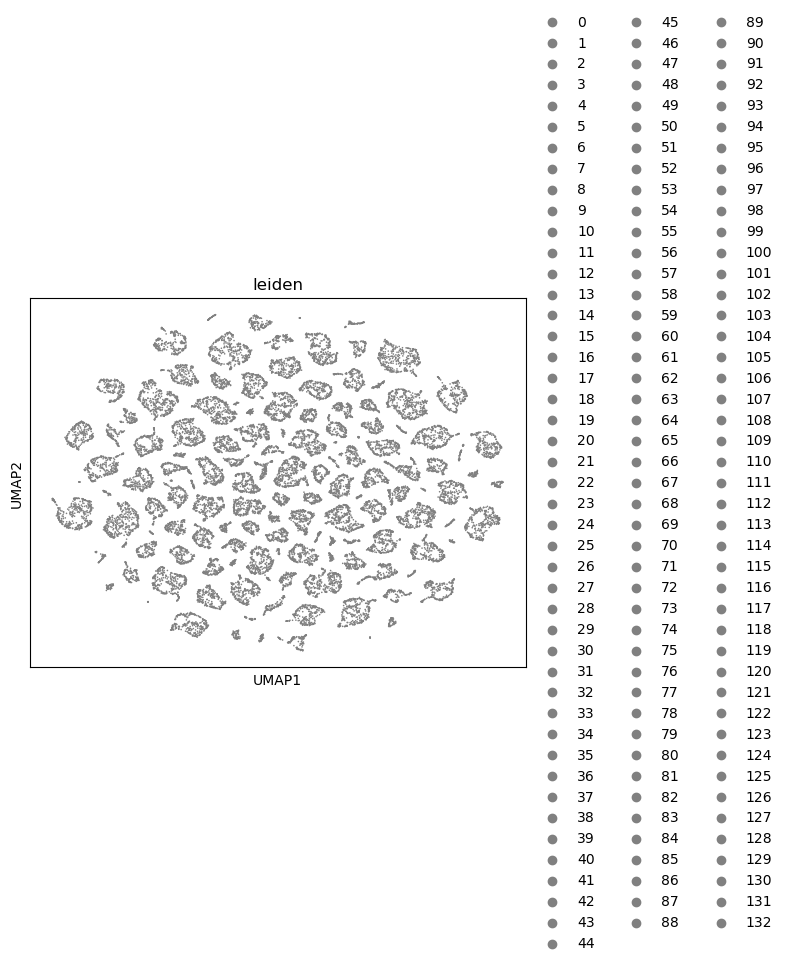

In [12]:
sc.pl.umap(adata_morphology_raw, color="leiden")

In [18]:
adata_morphology_df = adata_morphology_raw.to_df()

scaler = RobustMAD(epsilon=1e-18)
fitted_scaler = scaler.fit(adata_morphology_df)
fitted_scaled = fitted_scaler.transform(adata_morphology_df)

adata_morphology_df_scaled = pd.DataFrame(
    fitted_scaled,
    columns=adata_morphology_df.columns,
    index=adata_morphology_df.index,
)
adata_morphology_df_scaled

,inertia_tensor_0x0,inertia_tensor_0x1,inertia_tensor_1x0,inertia_tensor_1x1,perimeter_crofton,equivalent_diameter,eccentricity,feret_diameter_max,centroid_0,centroid_1,...,perimeter_1_2,equivalent_diameter_1_2,Correlation_Costes_1_1_2,Correlation_Costes_2_1_2,Correlation_Pearson_1_2,Correlation_Slope_1_2,Correlation_Manders_1_1_2,Correlation_Manders_2_1_2,Correlation_RWC_1_1_2,Correlation_RWC_2_1_2
s2-cell_121,0.122999,-7.851306e-01,-7.851306e-01,-0.696165,0.000000e+00,0.000000,-0.973397,8.333032e+15,0.000000,-1.000000e+18,...,0.000000e+00,0.000000,0.675266,0.0,3.406591,7.704934,-6.014521e+12,0.674491,3.632275,3.804269
s2-cell_147,0.122999,-7.851306e-01,-7.851306e-01,-0.696165,0.000000e+00,0.000000,-0.973397,8.333032e+15,0.000000,-1.000000e+18,...,0.000000e+00,0.000000,0.621323,0.0,3.392725,7.712430,-3.340260e+12,0.674491,2.816634,2.906853
s2-cell_157,0.079329,-1.587541e-01,-1.587541e-01,0.116062,0.000000e+00,0.000000,-0.566338,8.333032e+15,0.224590,-1.000000e+18,...,0.000000e+00,0.000000,0.672224,0.0,3.418923,7.725348,-4.283299e+12,0.674491,3.376308,3.525151
s2-cell_312,0.340563,0.000000e+00,0.000000e+00,-0.674491,0.000000e+00,0.000000,-1.128131,8.333032e+15,0.346914,0.000000e+00,...,0.000000e+00,0.000000,0.666608,0.0,3.406118,7.686722,0.000000e+00,0.669368,3.700753,3.882733
s2-cell_443,0.122999,-7.851306e-01,-7.851306e-01,-0.696165,0.000000e+00,0.000000,-0.973397,8.333032e+15,0.000000,0.000000e+00,...,0.000000e+00,0.000000,0.680716,0.0,3.410272,7.703553,-6.094377e+12,0.674491,3.805311,3.997076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-cell_32150,-0.254323,1.338070e+00,1.338070e+00,0.728344,0.000000e+00,0.000000,-0.044926,0.000000e+00,-0.485905,0.000000e+00,...,0.000000e+00,0.000000,0.435891,0.0,1.803143,-1.838536,0.000000e+00,0.615500,-4.084048,-4.469082
s2-cell_32756,-10064.988815,-5.552542e+13,-5.552542e+13,-7281.670583,-3.543741e+20,-23561.408400,551.473632,-4.600667e+19,-24.104057,-1.006717e+20,...,-3.766173e+20,-23561.408400,0.681824,0.0,-4.088443,-2.182243,0.000000e+00,0.674491,-7.824573,-8.738345
s2-cell_32780,-10065.905389,-1.880282e+15,-1.880282e+15,-7283.002380,-3.524780e+20,-23563.920805,551.516108,-4.500667e+19,-20.862756,-1.006630e+20,...,-3.790315e+20,-23563.920805,0.681824,0.0,0.139391,-2.078821,0.000000e+00,0.674491,-4.698970,-5.163975
s2-cell_32808,-10064.978453,1.664054e+15,1.664054e+15,-7285.649439,-3.543741e+20,-23562.245824,551.459060,-4.600667e+19,-24.202866,-1.006734e+20,...,-3.766173e+20,-23562.245824,0.681824,0.0,-0.410430,-2.025112,0.000000e+00,0.674491,-6.262058,-6.944950


In [19]:
feature_select_opts = [
    "variance_threshold",
    "drop_na_columns",
    "correlation_threshold",
    "blocklist",
    "drop_outliers",
]

adata_morphology_df_scaled_filtered = pycytominer.feature_select(
    profiles=adata_morphology_df_scaled,
    features=adata_morphology_df_scaled.columns.tolist(),
    samples="all",
    operation=feature_select_opts,
)
adata_morphology_df_scaled_filtered


,RadialDistribution_FracAtD_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_RadialCV_2of4_0,RadialDistribution_FracAtD_3of4_0,RadialDistribution_RadialCV_3of4_0,RadialDistribution_FracAtD_4of4_0,RadialDistribution_RadialCV_4of4_0,RadialDistribution_ZernikeMagnitude_1_1_0,RadialDistribution_ZernikePhase_1_1_0,...,Granularity_2_2,Granularity_16_2,Correlation_Pearson_0_1,Correlation_Slope_0_1,Correlation_RWC_1_0_1,Correlation_Slope_0_2,Correlation_RWC_2_0_2,Correlation_Pearson_1_2,Correlation_Slope_1_2,Correlation_RWC_2_1_2
s2-cell_121,0.946145,1.006057,-0.242293,-0.091675,0.234586,1.312707,-0.927408,-1.373791,15.416103,-0.691440,...,4.747064,1.701293,1.691094,1.160770,2.041876,7.344104,4.249721,3.406591,7.704934,3.804269
s2-cell_147,1.885397,-0.459167,-0.099768,-0.046669,-0.430852,0.653775,-1.336157,1.779686,24.201404,0.670220,...,3.602137,-0.368226,1.686148,1.148810,0.815871,7.336010,4.078837,3.392725,7.712430,2.906853
s2-cell_157,0.556331,1.697907,-1.415968,-0.383181,1.261774,1.654585,-0.394971,3.544972,34.368195,0.668595,...,0.309043,-1.031601,1.691216,1.152008,1.573847,7.338261,4.421026,3.418923,7.725348,3.525151
s2-cell_312,1.017841,-0.182880,-0.371694,-0.616815,-0.317766,0.414839,-0.315084,-1.113238,18.093655,-0.687470,...,4.111999,0.213425,1.690668,1.162865,2.017614,7.333332,4.567517,3.406118,7.686722,3.882733
s2-cell_443,0.959469,-0.552989,-0.690574,0.223465,-0.145489,0.238980,-0.110548,-2.243101,16.715660,-0.689551,...,3.857298,0.733801,1.691288,1.161390,2.112708,7.343103,4.523401,3.410272,7.703553,3.997076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-cell_32150,0.189693,-1.289520,0.848025,0.725216,-0.926504,-0.601220,-0.102885,-2.214250,-0.885634,-1.083801,...,4.236682,0.813351,-4.114824,-7.575211,-3.741910,-4.675519,3.662542,1.803143,-1.838536,-4.469082
s2-cell_32756,-1.333815,0.589213,-0.188450,-1.032688,2.801359,-1.526456,-1.289865,0.175912,35.572275,1.351695,...,-1.150603,-1.593761,-2.020999,0.907259,-6.321036,2.789948,3.319813,-4.088443,-2.182243,-8.738345
s2-cell_32780,0.503733,1.709597,1.355624,-1.491641,-0.221127,-1.337082,-1.630755,1.405021,35.802230,-1.365156,...,-2.144661,-2.108411,-4.942456,-11.847321,-7.019732,-6.755581,-1.325392,0.139391,-2.078821,-5.163975
s2-cell_32808,0.533077,0.088836,-0.197215,-0.077480,-0.736026,1.180114,0.411474,-1.941847,35.668897,1.351309,...,-2.029283,-1.903091,-3.560040,-4.073040,-6.222949,-0.418734,1.587309,-0.410430,-2.025112,-6.944950


In [20]:
adata_morphology_filtered = ad.AnnData(
    X=adata_morphology_df_scaled_filtered,
    obs=adata_morphology_raw.obs,
)
del adata_morphology_filtered.obs["leiden"]
adata_morphology_filtered

AnnData object with n_obs × n_vars = 22437 × 260
    obs: 'region', 'label_id', 'sample'

In [22]:
sc.pp.neighbors(adata_morphology_filtered)
sc.tl.umap(adata_morphology_filtered)
sc.tl.leiden(adata_morphology_filtered)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 260 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


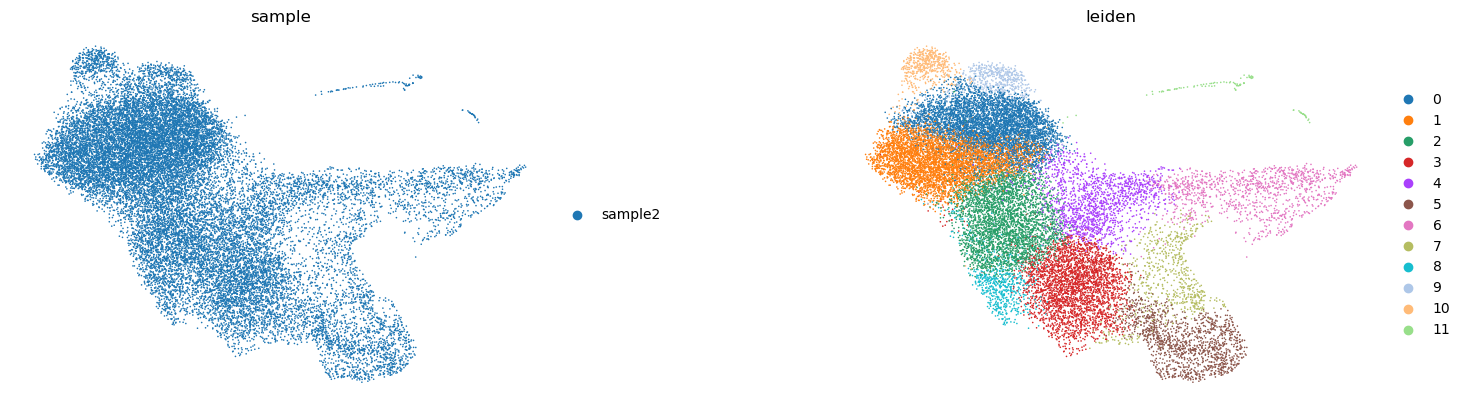

In [24]:
sc.pl.umap(
    adata_morphology_filtered,
    color=["sample", "leiden"],
    wspace=0.4,
    frameon=False,
)

In [25]:
sce.pp.harmony_integrate(adata_morphology_filtered, key="sample", max_iter_harmony=20)

2025-05-25 22:58:42,024 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


2025-05-25 22:58:47,671 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-25 22:58:47,794 - harmonypy - INFO - Iteration 1 of 20
2025-05-25 22:58:54,710 - harmonypy - INFO - Iteration 2 of 20
2025-05-25 22:59:01,585 - harmonypy - INFO - Iteration 3 of 20
2025-05-25 22:59:03,833 - harmonypy - INFO - Converged after 3 iterations


In [26]:
sc.pp.neighbors(adata_morphology_filtered, use_rep="X_pca_harmony")
sc.tl.umap(adata_morphology_filtered)
sc.tl.leiden(adata_morphology_filtered)

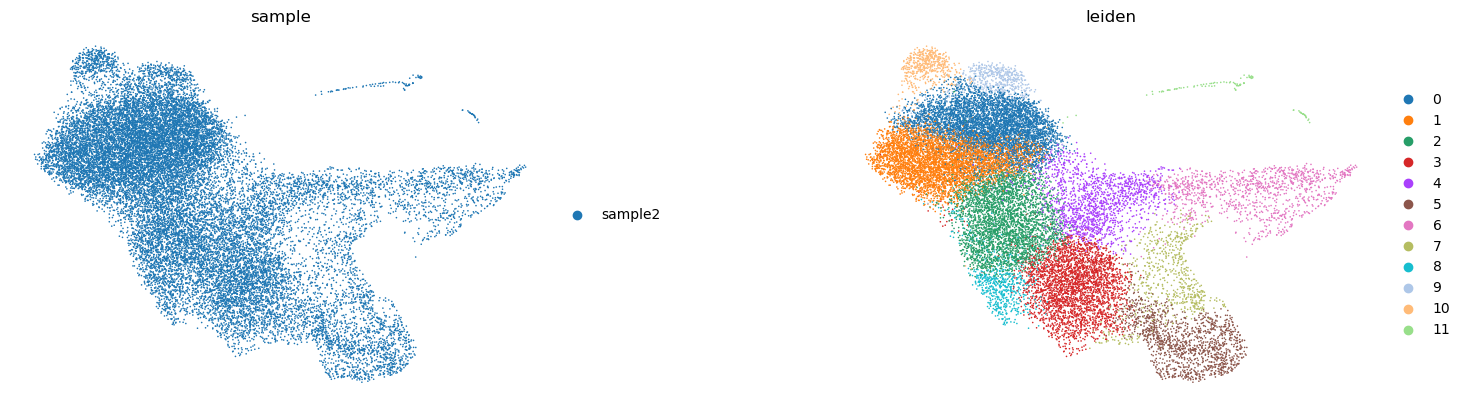

In [27]:
sc.pl.umap(
    adata_morphology_filtered,
    color=["sample", "leiden"],
    wspace=0.4,
    frameon=False,
)

In [28]:
adata_morphology_filtered

AnnData object with n_obs × n_vars = 22437 × 260
    obs: 'region', 'label_id', 'sample', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'sample_colors', 'leiden_colors'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [29]:
sdata_sample2.tables["morphology"].uns["spatialdata_attrs"]

{'instance_key': 'label_id',
 'region': 'filtered_hexes',
 'region_key': 'region'}

In [30]:
sdata_sample2.tables["morphology_filtered"] = TableModel.parse(
    adata_morphology_filtered[adata_morphology_filtered.obs["sample"] == "sample2"]
)
sdata_sample2.tables["morphology_filtered"].uns["spatialdata_attrs"] = sdata_sample2.tables["morphology"].uns["spatialdata_attrs"]

/tmp/ipykernel_4074207/4266652672.py:4: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  sdata_sample2.tables["morphology_filtered"].uns["spatialdata_attrs"] = sdata_sample2.tables["morphology"].uns["spatialdata_attrs"]


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


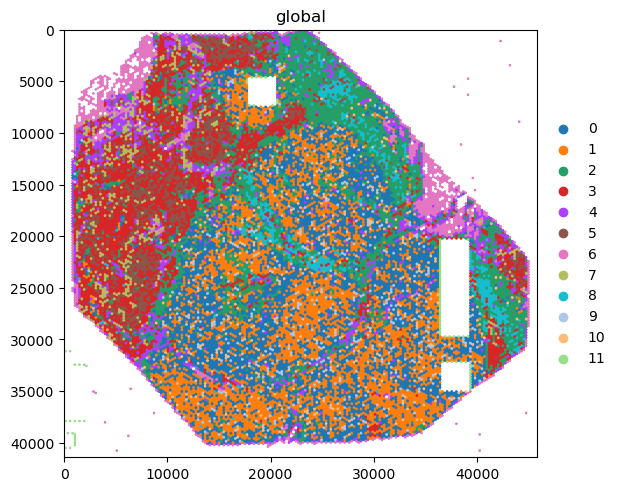

In [24]:
(
    sdata_sample2
    # .pl.render_images("hne_baked")
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show()
)

In [25]:
sdata_sample2.tables["morphology_filtered"]

AnnData object with n_obs × n_vars = 22437 × 260
    obs: 'region', 'label_id', 'sample', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'sample_colors', 'leiden_colors', 'spatialdata_attrs'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

## Load it celltypes for viz

In [70]:
xenium_celltypes = ad.read_h5ad(data_dir / "xenium_gexp_celltypes.h5ad")
xenium_celltypes

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B cells_score', 'Breast cancer_score', 'Breast glandular cells_score', 'Breast myoepithelial cells_score', 'Dendritic cells_score', 'Endothelial cells_score', 'Epithelial cells_score', 'Fibroblasts_score', 'Immune cells_score', 'Macrophages_score', 'Mast cells_score', 'Monocytes_score', 'NK cells_score', 'Smooth muscle cells_score', 'T cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'lo

In [76]:
xenium_celltypes[xenium_celltypes.obs["sample"] == "sample1"].obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region,sample,n_genes_by_counts,...,Epithelial cells_score,Fibroblasts_score,Immune cells_score,Macrophages_score,Mast cells_score,Monocytes_score,NK cells_score,Smooth muscle cells_score,T cells_score,predicted_celltype
0,1,89,0,0,89.0,686.555625,34.499375,cell_circles,sample1,50,...,0.275502,-0.155881,-0.056272,0.150137,0.562722,-0.037515,-0.038367,0.011410,-0.029879,Mast cells
1,2,61,0,0,61.0,277.259375,39.782656,cell_circles,sample1,45,...,-0.094056,0.151087,-0.215302,-0.038415,-0.023922,0.287070,-0.073399,-0.091561,-0.039396,Monocytes
2,3,192,0,0,192.0,222.033281,31.428750,cell_circles,sample1,85,...,-0.012356,0.653493,-0.384095,-0.083564,-0.017814,-0.119040,-0.005586,0.023378,-0.041284,Fibroblasts
3,4,146,0,0,146.0,98.124531,24.835938,cell_circles,sample1,57,...,-0.195588,-0.141091,-0.167731,-0.027516,0.000000,-0.087189,-0.028591,-0.031437,-0.043843,Breast glandular cells
4,5,202,0,0,202.0,115.690313,47.052813,cell_circles,sample1,68,...,0.099731,-0.071333,-0.308141,-0.026214,0.000000,-0.030670,-0.052524,-0.046702,-0.039594,Breast cancer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574522,574523,181,0,0,181.0,229.077656,28.448438,cell_circles,sample1,69,...,0.395028,-0.156849,-0.406485,-0.019659,0.000000,-0.105794,-0.069287,-0.078491,0.042203,Epithelial cells
574523,574524,238,0,0,238.0,313.248906,42.221094,cell_circles,sample1,87,...,0.308660,-0.056634,-0.214054,-0.075511,-0.017896,-0.086894,-0.048891,-0.102322,-0.019730,Epithelial cells
574524,574525,43,0,0,43.0,87.467656,33.009219,cell_circles,sample1,27,...,-0.318665,-0.039140,-0.212681,-0.033005,0.000000,-0.029338,-0.036252,-0.073661,-0.006409,Breast glandular cells
574525,574526,101,0,0,101.0,115.961250,15.759531,cell_circles,sample1,43,...,0.129355,-0.040115,-0.263855,0.035466,-0.017199,-0.034398,-0.044975,-0.021505,-0.024635,Breast cancer


In [100]:
sdata_sample1["table"].obs["predicted_celltype"] = xenium_celltypes[xenium_celltypes.obs["sample"] == "sample1"].obs["predicted_celltype"]
sdata_sample2["table"].obs["predicted_celltype"] = xenium_celltypes[xenium_celltypes.obs["sample"] == "sample2"].obs["predicted_celltype"].values

In [104]:
s2_celltypes = xenium_celltypes[xenium_celltypes.obs["sample"] == "sample2"].obs[["cell_id", "predicted_celltype"]]
s2_celltypes

,cell_id,predicted_celltype
0-1,1,Endothelial cells
1-1,2,Fibroblasts
2-1,3,Fibroblasts
3-1,4,Endothelial cells
4-1,5,Fibroblasts
...,...,...
365599-1,365600,Breast cancer
365600-1,365601,Breast cancer
365601-1,365602,Breast glandular cells
365602-1,365603,Monocytes


In [119]:
sdata_sample2["table"].obs = sdata_sample2["table"].obs.merge(s2_celltypes, left_on="cell_id", right_on="cell_id", how="left")

In [107]:
sdata_sample1["table"].uns["spatialdata_attrs"]["region"] = ["cell_labels"]
sdata_sample1["table"].obs["region"] = "cell_labels"

In [120]:
sdata_sample2["table"].uns["spatialdata_attrs"]["region"] = ["cell_labels"]
sdata_sample2["table"].obs["region"] = "cell_labels"

In [122]:
sdata_sample2["table"].uns

{'spatialdata_attrs': {'instance_key': 'cell_id',
  'region': ['cell_labels'],
  'region_key': 'region'},
 'predicted_celltype_colors': ['#1f77b4',
  '#ff7f0e',
  '#279e68',
  '#d62728',
  '#aa40fc',
  '#8c564b',
  '#e377c2',
  '#b5bd61',
  '#17becf',
  '#aec7e8',
  '#ffbb78',
  '#98df8a',
  '#ff9896',
  '#c5b0d5',
  '#c49c94',
  '#f7b6d2',
  '#dbdb8d']}

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


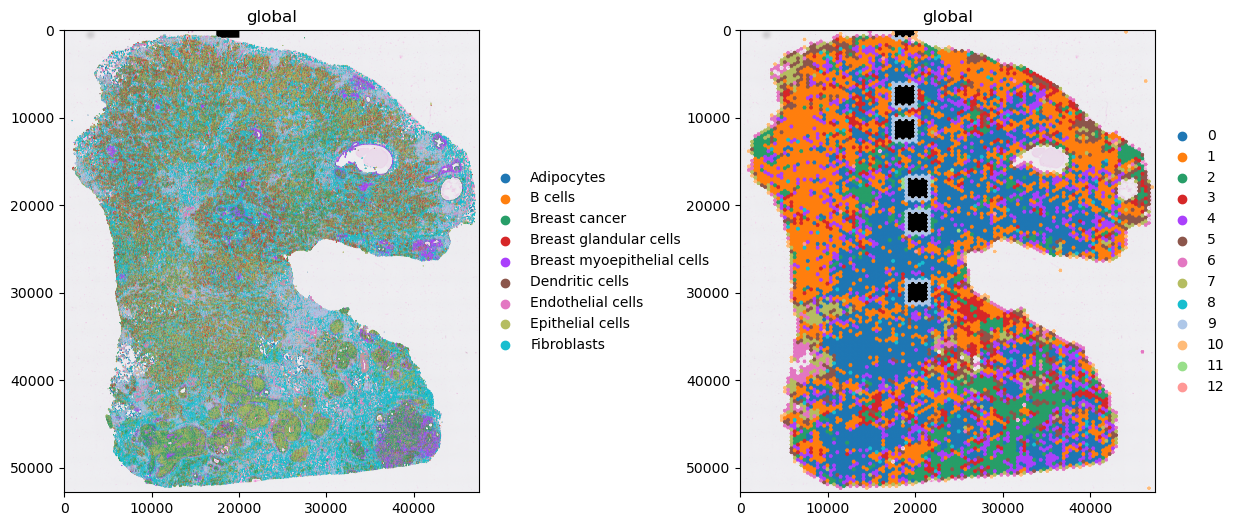

In [109]:
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 6))

(
    sdata_sample1
    .pl.render_images("hne_baked")
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[0])
)

(
    sdata_sample1
    .pl.render_images("hne_baked")
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[1])
)

In [56]:
sdata_sample2.tables["morphology_filtered"] = TableModel.parse(
    adata_morphology_filtered[adata_morphology_filtered.obs["sample"] == "sample2"]
)
sdata_sample2.tables["morphology_filtered"].uns["spatialdata_attrs"] = sdata_sample2.tables["morphology"].uns["spatialdata_attrs"]

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `morphology_filtered` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/tmp/ipykernel_1524218/4266652672.py:4: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  sdata_sample2.tables["morphology_filtered"].uns["spatialdata_attrs"] = sdata_sample2.tables["morphology"].uns["spatialdata_attrs"]


In [57]:
sdata_sample2.tables["morphology_filtered"]

AnnData object with n_obs × n_vars = 8148 × 252
    obs: 'region', 'label_id', 'sample', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'sample_colors', 'leiden_colors', 'spatialdata_attrs'
    obsm: 'X_pca', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [58]:
del sdata_sample2.tables["morphology_filtered"].uns["leiden_colors"]

In [ ]:
sdata_sample2.tables["morphology_filtered"].uns["leiden_colors"]

INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


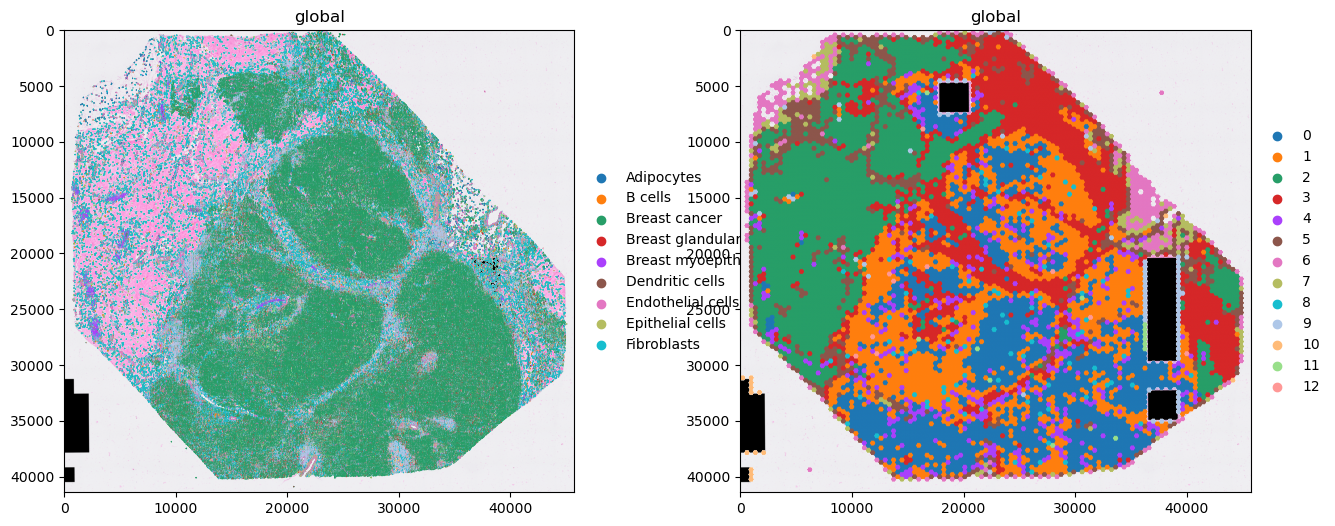

In [123]:
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 6))

(
    sdata_sample2
    .pl.render_images("hne_baked")
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[0])
)

(
    sdata_sample2
    .pl.render_images("hne_baked")
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[1])
)

In [162]:
for table in sdata_sample1.tables:

    print(table, type(sdata_sample1.tables[table].obs["region"].values))

morphology <class 'pandas.core.arrays.categorical.Categorical'>
table <class 'numpy.ndarray'>
table_subset <class 'pandas.core.arrays.categorical.Categorical'>
morphology_filtered <class 'pandas.core.arrays.categorical.Categorical'>


In [167]:
sdata_sample1.tables["table"].obs["region"] = pd.Categorical(sdata_sample1.tables["table"].obs["region"])

In [168]:
for table in sdata_sample1.tables:

    print(table, type(sdata_sample1.tables[table].obs["region"].values))

morphology <class 'pandas.core.arrays.categorical.Categorical'>
table <class 'pandas.core.arrays.categorical.Categorical'>
table_subset <class 'pandas.core.arrays.categorical.Categorical'>
morphology_filtered <class 'pandas.core.arrays.categorical.Categorical'>


In [169]:
sdata_sample1.write(data_dir / "xenium_sample1_hexes_measured_processed.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes_measured_processed.zarr)
         . Please see the documentation of `is_self_contained()` to understand the implications of working with    
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes_measured.zarr the new   
         file path:                                                                                                
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xe

In [170]:
for table in sdata_sample2.tables:

    print(table, type(sdata_sample2.tables[table].obs["region"].values))

morphology <class 'pandas.core.arrays.categorical.Categorical'>
table <class 'numpy.ndarray'>
table_subset <class 'pandas.core.arrays.categorical.Categorical'>
morphology_filtered <class 'pandas.core.arrays.categorical.Categorical'>


In [27]:
sdata_sample2.tables["table"].obs["region"] = pd.Categorical(sdata_sample2.tables["table"].obs["region"])

In [28]:
for table in sdata_sample2.tables:

    print(table, type(sdata_sample2.tables[table].obs["region"].values))

morphology <class 'pandas.core.arrays.categorical.Categorical'>
table <class 'pandas.core.arrays.categorical.Categorical'>
morphology_filtered <class 'pandas.core.arrays.categorical.Categorical'>


In [29]:
sdata_sample2.write(data_dir / "xenium_sample2_hexes300_measured_processed.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes300_measured_processed.za
         rr). Please see the documentation of `is_self_contained()` to understand the implications of working with 
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes300_measured.zarr the new
         file path:                                                                                                
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xe

### Use leiden clusters on hexes to extract contained celltypes
1) find cells whose centroids fall into hexes of a given leiden cluster
2) subset the respective anndata to only these cells
3) calculate celltype fractions per cluster

In [30]:
sdata_sample2["morphology"].to_df()

,inertia_tensor_0x0,inertia_tensor_0x1,inertia_tensor_1x0,inertia_tensor_1x1,perimeter_crofton,equivalent_diameter,eccentricity,feret_diameter_max,centroid_0,centroid_1,...,perimeter_1_2,equivalent_diameter_1_2,Correlation_Costes_1_1_2,Correlation_Costes_2_1_2,Correlation_Pearson_1_2,Correlation_Slope_1_2,Correlation_Manders_1_1_2,Correlation_Manders_2_1_2,Correlation_RWC_1_1_2,Correlation_RWC_2_1_2
s2-cell_121,4686.499222,-9.038809e-17,-9.038809e-17,4693.093498,894.107752,272.885852,0.037485,300.015000,130.471600,149.500000,...,940.264069,272.885852,0.999997,1.0,0.999590,1.012985,0.999994,1.000000,0.983482,0.983381
s2-cell_147,4686.499222,-9.038809e-17,-9.038809e-17,4693.093498,894.107752,272.885852,0.037485,300.015000,130.471600,149.500000,...,940.264069,272.885852,0.999973,1.0,0.999315,1.013513,0.999997,1.000000,0.944400,0.944450
s2-cell_157,4686.480209,-1.992426e-17,-1.992426e-17,4693.311586,894.107752,272.885852,0.038152,300.015000,130.498786,149.500000,...,940.264069,272.885852,0.999996,1.0,0.999834,1.014423,0.999996,1.000000,0.971218,0.971272
s2-cell_312,4686.593946,-2.065319e-18,-2.065319e-18,4693.099318,894.107752,272.885852,0.037231,300.015000,130.513593,150.500000,...,940.264069,272.885852,0.999993,1.0,0.999581,1.011702,1.000000,0.999997,0.986764,0.986784
s2-cell_443,4686.499222,-9.038809e-17,-9.038809e-17,4693.093498,894.107752,272.885852,0.037485,300.015000,130.471600,150.500000,...,940.264069,272.885852,1.000000,1.0,0.999663,1.012888,0.999994,1.000000,0.991774,0.991745
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s2-cell_32150,4686.334943,1.484600e-16,1.484600e-16,4693.475987,894.107752,272.885852,0.039006,300.006667,130.412783,150.500000,...,940.264069,272.885852,0.999890,1.0,0.967800,0.340819,1.000000,0.999964,0.613749,0.624478
s2-cell_32756,304.341899,-6.246297e-03,-6.246297e-03,2738.107102,539.733664,109.899728,0.942788,254.000000,127.553869,49.828273,...,563.646753,109.899728,1.000000,1.0,0.850995,0.316611,1.000000,1.000000,0.434518,0.439275
s2-cell_32780,303.942841,-2.115212e-01,-2.115212e-01,2737.749507,541.629783,109.882349,0.942858,255.000000,127.946220,49.836971,...,561.232539,109.882349,1.000000,1.0,0.934815,0.323895,1.000000,1.000000,0.584284,0.594333
s2-cell_32808,304.346411,1.871967e-01,1.871967e-01,2737.038755,539.733664,109.893936,0.942764,254.000000,127.541908,49.826568,...,563.646753,109.893936,1.000000,1.0,0.923914,0.327678,1.000000,1.000000,0.509388,0.517073


In [35]:

def subset_mask_by_leiden(
    hex_seg: np.ndarray,
    adata: ad.AnnData,
    target_cluster: str,
    cell_id_col: str,
    leiden_key: str = "leiden",
) -> np.ndarray:
    """
    Subset a hex-based segmentation mask to a binary mask for a given Leiden cluster.

    Parameters
    ----------
    hex_seg : np.ndarray
        2D array of integer hex IDs (shape: H x W).
    adata : anndata.AnnData
        Annotated data object with at least:
          - adata.obs[hex_label_key]: hex ID for each observation
          - adata.obs[leiden_key]: Leiden cluster ID (as string) for each hex
    target_cluster : str
        The Leiden cluster ID to isolate (e.g. "0", "1", "2", ...).
    leiden_key : str, optional
        Column name in adata.obs containing Leiden cluster IDs (default: "leiden").
    hex_label_key : str, optional
        Column name in adata.obs containing hex labels/IDs (default: "hex_label").

    Returns
    -------
    np.ndarray
        2D binary mask (dtype uint8) of the same shape as `hex_seg`, where
        pixels belonging to hexes in `target_cluster` are 1, and all others are 0.
    """
    # 1. Select hex IDs belonging to the target Leiden cluster
    mask_obs = adata.obs[leiden_key] == target_cluster
    cell_ids_in_cluster = adata.obs.loc[mask_obs, cell_id_col].unique()

    # 2. Build the binary mask
    binary_mask = np.isin(hex_seg, cell_ids_in_cluster).astype(np.uint8)

    return binary_mask



try:
    import dask.array as da
    from dask.diagnostics import ProgressBar
except ImportError:
    da = None  # Dask not available

def extract_cell_labels_in_mask(cell_seg, binary_mask) -> np.ndarray:
    """
    Multiply a labeled cell segmentation image by a binary mask
    and return the unique cell labels present in the masked region.
    Works with both NumPy and Dask arrays (shows a progress bar for Dask).
    
    Parameters
    ----------
    cell_seg : np.ndarray or dask.array.Array
        2D array of integer cell IDs (shape: H x W).
    binary_mask : np.ndarray or dask.array.Array
        2D binary (0/1) mask of the same shape as `cell_seg`.
    
    Returns
    -------
    np.ndarray
        1D array of unique cell IDs found within the mask (excluding 0).
    """
    # 1. Shape check
    if cell_seg.shape != binary_mask.shape:
        raise ValueError(
            f"Shape mismatch: cell_seg.shape = {cell_seg.shape}, "
            f"binary_mask.shape = {binary_mask.shape}"
        )

    # 2. Apply mask
    masked = cell_seg * binary_mask

    # 3. Unique extraction
    if da is not None and isinstance(masked, da.Array):
        # Use Dask's unique + progress bar
        with ProgressBar():
            unique_labels = da.unique(masked).compute()
    else:
        # Pure NumPy path
        unique_labels = np.unique(masked)

    # 4. Exclude background 0 and return
    return unique_labels[unique_labels != 0]

In [133]:
cluster_3_mask = subset_mask_by_leiden(
    sdata_sample1.labels["filtered_hexes"]["scale0"].image.data, 
    sdata_sample1.tables["morphology_filtered"], 
    target_cluster="3",
    cell_id_col="label_id"
)


In [142]:
labels_in_c3 = extract_cell_labels_in_mask(
    sdata_sample1.labels["cell_labels"]["scale0"].image.data,
    cluster_3_mask
)


[########################################] | 100% Completed | 207.86 s


In [147]:
celltypes_in_s1_c3 = sdata_sample1.tables["table"][sdata_sample1.tables["table"].obs.cell_id.isin(labels_in_c3)].obs.predicted_celltype.value_counts()

predicted_celltype
Fibroblasts                   10963
Immune cells                   7269
Epithelial cells               5618
Breast cancer                  4506
Breast glandular cells         2347
Monocytes                      1886
Endothelial cells              1703
Breast myoepithelial cells     1168
Macrophages                     365
Smooth muscle cells             365
Mast cells                      352
NK cells                        162
Dendritic cells                 127
B cells                         110
T cells                          95
Adipocytes                       48
Unknown                           5
Name: count, dtype: int64

In [149]:

# References to your data containers
hex_seg = sdata_sample1.labels["filtered_hexes"]["scale0"].image.data
cell_seg = sdata_sample1.labels["cell_labels"]["scale0"].image.data
morph_df = sdata_sample1.tables["morphology_filtered"]
meta_table = sdata_sample1.tables["table"]

# Get the list of all Leiden clusters present
clusters = morph_df.obs["leiden"].unique()

# Prepare a list to collect results
records = []

for cluster in clusters:
    # 1. Subset hex mask for this cluster
    mask = subset_mask_by_leiden(
        hex_seg,
        morph_df,
        target_cluster=str(cluster),
        leiden_key="leiden",
        cell_id_col="label_id"   # adjust if your hex‐ID column is named differently
    )
    
    # 2. Extract cell labels inside that mask
    labels = extract_cell_labels_in_mask(cell_seg, mask)
    
    # 3. Pull out predicted celltypes for those labels and count
    ct_counts = (
        meta_table
        .obs
        .loc[meta_table.obs["cell_id"].isin(labels), "predicted_celltype"]
        .value_counts()
    )
    
    # 4. Append each celltype count to our records
    for celltype, count in ct_counts.items():
        records.append({
            "leiden_cluster": cluster,
            "celltype": celltype,
            "count": int(count)
        })

# Build a DataFrame of results
results_df = pd.DataFrame.from_records(records)

# (Optional) pivot so clusters are rows and celltypes are columns
pivot_df = results_df.pivot_table(
    index="leiden_cluster",
    columns="celltype",
    values="count",
    fill_value=0
)

[########################################] | 100% Completed | 202.35 s
[########################################] | 100% Completed | 199.50 s
[###                                     ] | 8% Completed | 28.99 sms

IOStream.flush timed out


[########################################] | 100% Completed | 205.44 s
[########################################] | 100% Completed | 201.76 s
[########################################] | 100% Completed | 203.26 s
[########################################] | 100% Completed | 207.32 s
[########################################] | 100% Completed | 210.04 s
[########################################] | 100% Completed | 194.48 s
[########################################] | 100% Completed | 201.48 s
[########################################] | 100% Completed | 203.36 s
[########################################] | 100% Completed | 199.63 s
[########################################] | 100% Completed | 185.17 s
[####################################    ] | 90% Completed | 148.34 s

IOStream.flush timed out


[########################################] | 100% Completed | 199.86 s


In [150]:
pivot_df

celltype,Adipocytes,B cells,Breast cancer,Breast glandular cells,Breast myoepithelial cells,Dendritic cells,Endothelial cells,Epithelial cells,Fibroblasts,Immune cells,Macrophages,Mast cells,Monocytes,NK cells,Smooth muscle cells,T cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,116.0,265.0,50214.0,27129.0,8871.0,316.0,5715.0,60627.0,32732.0,15178.0,729.0,1239.0,5560.0,386.0,1612.0,222.0,5.0
1,281.0,868.0,41914.0,27861.0,8828.0,933.0,8183.0,47242.0,34554.0,34020.0,1606.0,1594.0,6929.0,779.0,1794.0,996.0,79.0
10,8.0,6.0,259.0,98.0,104.0,6.0,52.0,215.0,155.0,152.0,8.0,17.0,54.0,2.0,7.0,6.0,0.0
11,0.0,0.0,200.0,93.0,20.0,0.0,17.0,199.0,122.0,46.0,2.0,1.0,32.0,1.0,1.0,1.0,0.0
12,0.0,0.0,138.0,100.0,8.0,3.0,11.0,170.0,158.0,59.0,3.0,1.0,19.0,1.0,3.0,0.0,0.0
2,59.0,100.0,1868.0,792.0,433.0,61.0,2188.0,1478.0,15250.0,6242.0,229.0,507.0,1999.0,80.0,782.0,55.0,0.0
3,48.0,110.0,4506.0,2347.0,1168.0,127.0,1703.0,5618.0,10963.0,7269.0,365.0,352.0,1886.0,162.0,365.0,95.0,5.0
4,128.0,307.0,13887.0,6801.0,3837.0,228.0,4546.0,14189.0,21652.0,11750.0,564.0,966.0,3135.0,248.0,1121.0,172.0,1.0
5,288.0,159.0,5889.0,2411.0,2573.0,135.0,1995.0,5609.0,6894.0,5207.0,357.0,314.0,1288.0,115.0,499.0,90.0,74.0


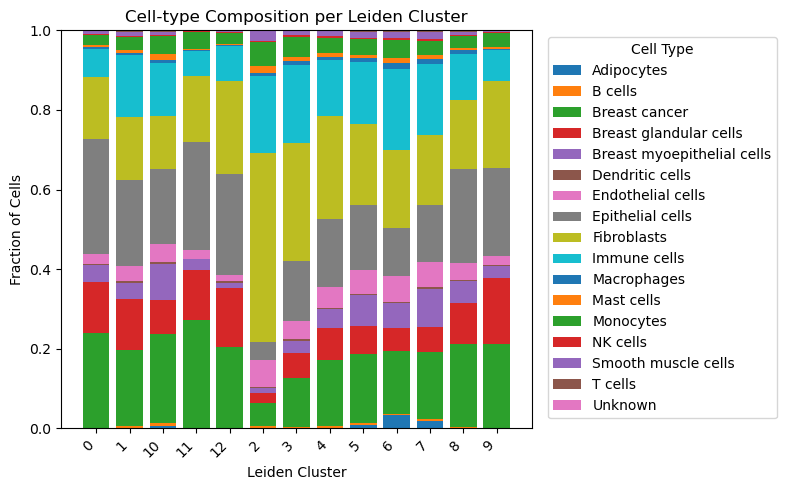

In [151]:
# 1. Compute per‐cluster fractions
fractions = pivot_df.div(pivot_df.sum(axis=1), axis=0)

# 2. Plot stacked bars
clusters = fractions.index.astype(str).tolist()
celltypes = fractions.columns.tolist()
bottom = np.zeros(len(clusters))

fig, ax = plt.subplots(figsize=(8, 5))
for ct in celltypes:
    ax.bar(clusters, fractions[ct], bottom=bottom, label=ct)
    bottom += fractions[ct].values

# 3. Formatting
ax.set_xlabel("Leiden Cluster")
ax.set_ylabel("Fraction of Cells")
ax.set_title("Cell‐type Composition per Leiden Cluster")
ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

# 1. Generate the mapping DataFrame
celltypes = pivot_df.columns.tolist()
n_types = len(celltypes)

cmap = plt.get_cmap("tab20")
# sample n_types positions evenly in [0,1)
positions = np.linspace(0, 1, n_types, endpoint=True)
# convert each RGBA to hex
hex_colors = [matplotlib.colors.to_hex(cmap(pos)) for pos in positions]

# Build the DataFrame
color_df = pd.DataFrame({
    "celltype": celltypes,
    "hex_color": hex_colors
})
# color_df["hex_color"] = color_df["hex_color"].sample(frac=1).reset_index(drop=True)

# Now color_df looks like:
#              celltype hex_color
# 0           Adipocytes   #ff0000
# 1               B cells  #ff8000
# ...                ...       ...
# 16             Unknown  #7f00ff

# 2. Updated plotting function
def plot_celltype_fractions_with_mapping(pivot_df, color_df):
    """
    Stacked bar plot of cell‐type fractions, using exact hex colors
    from color_df. Bars sorted by integer Leiden cluster.
    """
    # Sort clusters by int value of the index (which are strings)
    clusters_sorted = sorted(pivot_df.index, key=lambda s: int(s))
    df_sorted = pivot_df.loc[clusters_sorted]
    fractions = df_sorted.div(df_sorted.sum(axis=1), axis=0)

    # Build a mapping from celltype -> hex color
    color_map = dict(zip(color_df["celltype"], color_df["hex_color"]))

    bottom = np.zeros(len(clusters_sorted))
    fig, ax = plt.subplots(figsize=(8, 5))
    for ct in fractions.columns:
        ax.bar(
            clusters_sorted,
            fractions[ct],
            bottom=bottom,
            label=ct,
            color=color_map.get(ct, "#333333")  # fallback gray if missing
        )
        bottom += fractions[ct].values

    ax.set_xlabel("Leiden Cluster")
    ax.set_ylabel("Fraction of Cells")
    ax.set_title("Cell‐type Composition per Leiden Cluster")
    ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_xticklabels(clusters_sorted, rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

plot_celltype_fractions_with_mapping(pivot_df, color_df)

NameError: name 'pivot_df' is not defined

In [181]:
pivot_df.to_csv(data_dir / "xenium_sample1_celltype_fractions_per_leiden.csv")

### Repeat for sample2

In [31]:
gene_groups_10x = pd.read_csv(data_dir / "Xenium_V1_FFPE_Human_Breast_Addon_Input_gene_groups.csv")
marker_dict = (
    gene_groups_10x.dropna(subset=["group"])
      .groupby("group")["gene"]
      .apply(list)
      .to_dict()
)

In [32]:
for ct, genes in marker_dict.items():
    sc.tl.score_genes(
      sdata_sample2.tables["table"],
      gene_list=genes,
      score_name=f"{ct}_score",
      use_raw=False
    )

In [33]:
score_cols = [f"{ct}_score" for ct in marker_dict]

max_scores = sdata_sample2.tables["table"].obs[score_cols].max(axis=1)
best_ct   = sdata_sample2.tables["table"].obs[score_cols].idxmax(axis=1).str.replace("_score", "")

# assign, with an optional threshold
threshold = 0.0
sdata_sample2.tables["table"].obs["predicted_celltype"] = np.where(
    max_scores > threshold,
    best_ct,
    "Unknown"
)

sdata_sample2.tables["table"].obs["predicted_celltype"] 

0         Endothelial cells
1               Fibroblasts
2               Fibroblasts
3         Endothelial cells
4               Fibroblasts
                ...        
365599     Epithelial cells
365600        Breast cancer
365601     Epithelial cells
365602            Monocytes
365603     Epithelial cells
Name: predicted_celltype, Length: 365604, dtype: object

In [36]:

# References to your data containers
hex_seg = sdata_sample2.labels["filtered_hexes"]["scale0"].image.data
cell_seg = sdata_sample2.labels["cell_labels"]["scale0"].image.data
morph_df = sdata_sample2.tables["morphology_filtered"]
meta_table = sdata_sample2.tables["table"]

# Get the list of all Leiden clusters present
clusters = morph_df.obs["leiden"].unique()

# Prepare a list to collect results
records_s2 = []

for cluster in clusters:
    # 1. Subset hex mask for this cluster
    mask = subset_mask_by_leiden(
        hex_seg,
        morph_df,
        target_cluster=str(cluster),
        leiden_key="leiden",
        cell_id_col="label_id"   # adjust if your hex‐ID column is named differently
    )
    
    # 2. Extract cell labels inside that mask
    labels = extract_cell_labels_in_mask(cell_seg, mask)
    
    # 3. Pull out predicted celltypes for those labels and count
    ct_counts = (
        meta_table
        .obs
        .loc[meta_table.obs["cell_id"].isin(labels), "predicted_celltype"]
        .value_counts()
    )
    
    # 4. Append each celltype count to our records
    for celltype, count in ct_counts.items():
        records_s2.append({
            "leiden_cluster": cluster,
            "celltype": celltype,
            "count": int(count)
        })

# Build a DataFrame of results
results_df_s2 = pd.DataFrame.from_records(records_s2)

# (Optional) pivot so clusters are rows and celltypes are columns
pivot_df_s2 = results_df_s2.pivot_table(
    index="leiden_cluster",
    columns="celltype",
    values="count",
    fill_value=0
)

[########################################] | 100% Completed | 305.51 s
[########################################] | 100% Completed | 298.19 s
[########################################] | 100% Completed | 303.83 s
[########################################] | 100% Completed | 299.07 s
[########################################] | 100% Completed | 306.33 s
[########################################] | 100% Completed | 310.77 s
[########################################] | 100% Completed | 313.72 s
[########################################] | 100% Completed | 294.55 s
[########################################] | 100% Completed | 288.85 s
[########################################] | 100% Completed | 297.53 s
[########################################] | 100% Completed | 289.28 s
[########################################] | 100% Completed | 282.78 s


In [37]:
pivot_df_s2

celltype,Adipocytes,B cells,Breast cancer,Breast glandular cells,Breast myoepithelial cells,Dendritic cells,Endothelial cells,Epithelial cells,Fibroblasts,Immune cells,Macrophages,Mast cells,Monocytes,NK cells,Smooth muscle cells,T cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,146.0,321.0,105775.0,1975.0,728.0,479.0,3967.0,24343.0,7110.0,11736.0,898.0,1265.0,2590.0,382.0,1108.0,391.0,3.0
1,97.0,201.0,92509.0,1734.0,558.0,318.0,3383.0,20486.0,6317.0,7935.0,877.0,1249.0,2478.0,327.0,1091.0,172.0,4.0
10,22.0,74.0,12585.0,260.0,72.0,89.0,519.0,3147.0,906.0,1621.0,125.0,158.0,363.0,53.0,130.0,65.0,0.0
11,1.0,2.0,1845.0,24.0,3.0,2.0,51.0,413.0,59.0,111.0,8.0,7.0,26.0,3.0,13.0,2.0,0.0
2,140.0,363.0,17792.0,707.0,748.0,337.0,3525.0,7763.0,9754.0,8637.0,735.0,858.0,1930.0,301.0,1437.0,327.0,10.0
3,101.0,163.0,804.0,60.0,253.0,75.0,1424.0,453.0,6093.0,2294.0,288.0,298.0,742.0,63.0,597.0,70.0,3.0
4,247.0,126.0,5410.0,157.0,237.0,98.0,1793.0,2023.0,3890.0,2560.0,184.0,291.0,595.0,80.0,743.0,89.0,12.0
5,17.0,25.0,85.0,5.0,20.0,12.0,155.0,60.0,1361.0,343.0,56.0,58.0,169.0,13.0,69.0,13.0,0.0
6,297.0,30.0,1396.0,32.0,18.0,18.0,640.0,660.0,887.0,612.0,37.0,74.0,154.0,21.0,208.0,26.0,1.0


/tmp/ipykernel_4074207/3312620101.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(clusters_sorted, rotation=45, ha="right")


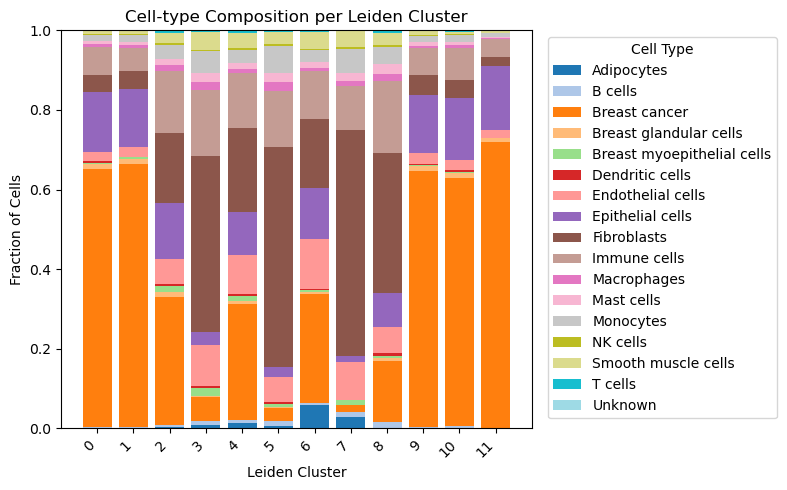

In [42]:
def plot_celltype_fractions_with_mapping(pivot_df, color_df):
    """
    Stacked bar plot of cell‐type fractions, using exact hex colors
    from color_df. Bars sorted by integer Leiden cluster.
    """
    # Sort clusters by int value of the index (which are strings)
    clusters_sorted = sorted(pivot_df.index, key=lambda s: int(s))
    df_sorted = pivot_df.loc[clusters_sorted]
    fractions = df_sorted.div(df_sorted.sum(axis=1), axis=0)

    # Build a mapping from celltype -> hex color
    color_map = dict(zip(color_df["celltype"], color_df["hex_color"]))

    bottom = np.zeros(len(clusters_sorted))
    fig, ax = plt.subplots(figsize=(8, 5))
    for ct in fractions.columns:
        ax.bar(
            clusters_sorted,
            fractions[ct],
            bottom=bottom,
            label=ct,
            color=color_map.get(ct, "#333333")  # fallback gray if missing
        )
        bottom += fractions[ct].values

    ax.set_xlabel("Leiden Cluster")
    ax.set_ylabel("Fraction of Cells")
    ax.set_title("Cell‐type Composition per Leiden Cluster")
    ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_xticklabels(clusters_sorted, rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# 1. Generate the mapping DataFrame
celltypes = pivot_df_s2.columns.tolist()
n_types = len(celltypes)

cmap = plt.get_cmap("tab20")
# sample n_types positions evenly in [0,1)
positions = np.linspace(0, 1, n_types, endpoint=True)
# convert each RGBA to hex
hex_colors = [matplotlib.colors.to_hex(cmap(pos)) for pos in positions]

# Build the DataFrame
color_df = pd.DataFrame({
    "celltype": celltypes,
    "hex_color": hex_colors
})

plot_celltype_fractions_with_mapping(pivot_df_s2, color_df)

In [187]:
pivot_df_s2.to_csv(data_dir / "xenium_sample2_celltype_fractions_per_leiden.csv")

/tmp/ipykernel_1524218/1193650355.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(clusters, rotation=45, ha="right")


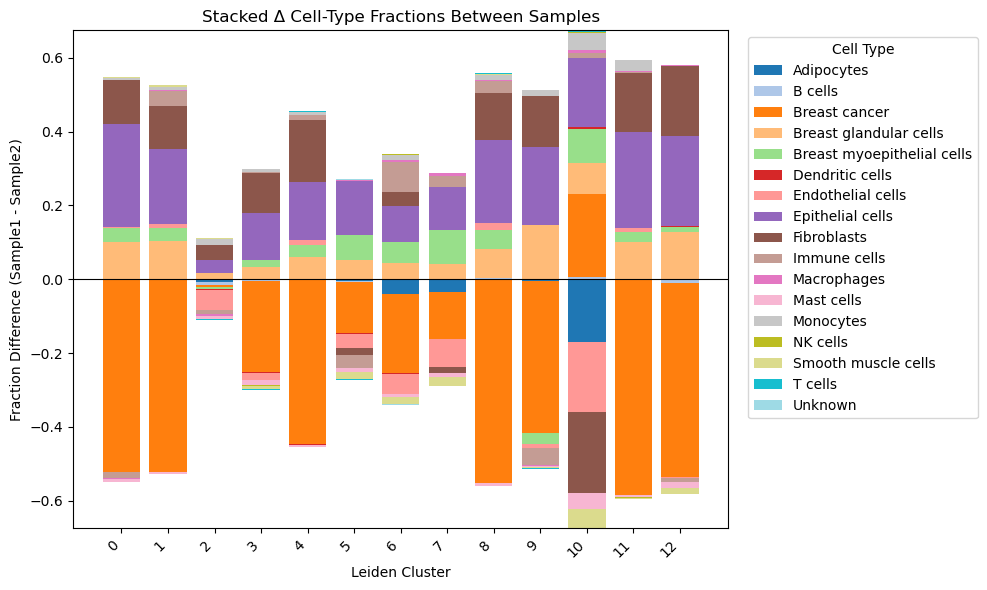

In [189]:

def plot_delta_stacked(pivot_df1, pivot_df2, color_df):
    """
    Stacked bar chart of fraction differences (sample1 - sample2) per cluster,
    stacking positives upward and negatives downward.

    Parameters
    ----------
    pivot_df1 : pandas.DataFrame
        Counts per cluster (rows) and celltype (columns) for sample 1.
    pivot_df2 : pandas.DataFrame
        Counts per cluster (rows) and celltype (columns) for sample 2.
    color_df : pandas.DataFrame
        Mapping DataFrame with columns ["celltype", "hex_color"].
    """
    # 1. Sort clusters by integer value of their string index
    clusters = sorted(pivot_df1.index, key=lambda s: int(s))
    
    # 2. Compute fraction tables in that order
    df1 = pivot_df1.loc[clusters]
    df2 = pivot_df2.loc[clusters]
    frac1 = df1.div(df1.sum(axis=1), axis=0)
    frac2 = df2.div(df2.sum(axis=1), axis=0)
    
    # 3. Delta DataFrame
    delta = frac1 - frac2
    
    # 4. Color map
    cmap = dict(zip(color_df["celltype"], color_df["hex_color"]))
    
    # 5. Prepare bottoms
    pos_bot = np.zeros(len(clusters))
    neg_bot = np.zeros(len(clusters))
    
    # 6. Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    for ct in delta.columns:
        h = delta[ct].values
        pos_h = np.where(h > 0, h, 0)
        neg_h = np.where(h < 0, h, 0)
        
        # positive stack
        ax.bar(clusters, pos_h, bottom=pos_bot, color=cmap.get(ct, "#888888"), label=ct)
        pos_bot += pos_h
        
        # negative stack
        ax.bar(clusters, neg_h, bottom=neg_bot, color=cmap.get(ct, "#888888"))
        neg_bot += neg_h
    
    # 7. Zero line and formatting
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Leiden Cluster")
    ax.set_ylabel("Fraction Difference (Sample1 - Sample2)")
    ax.set_title("Stacked Δ Cell‐Type Fractions Between Samples")
    ax.set_xticklabels(clusters, rotation=45, ha="right")
    ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_delta_stacked(pivot_df, pivot_df_s2, color_df)


/tmp/ipykernel_1524218/1193650355.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(clusters, rotation=45, ha="right")


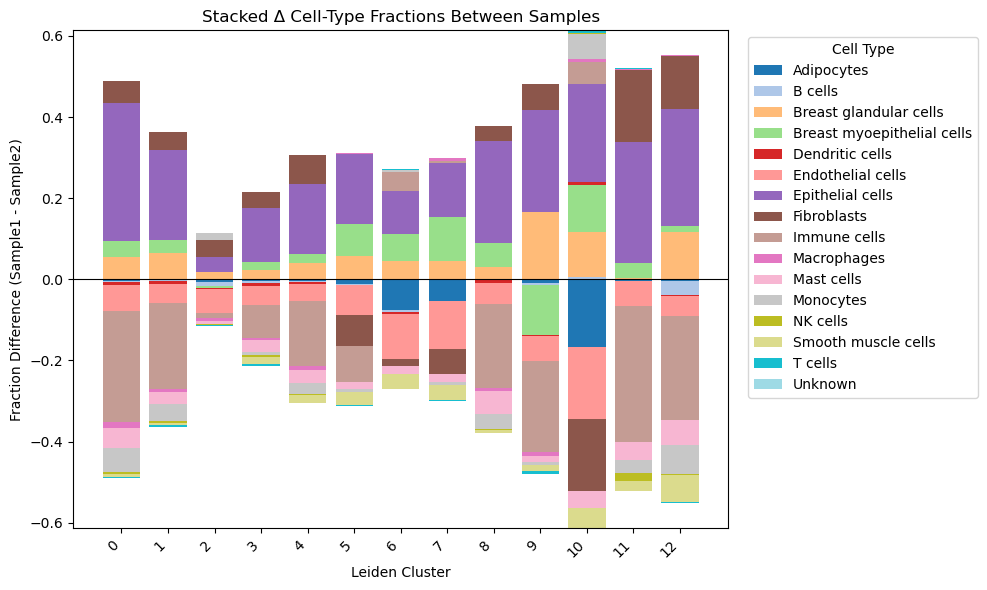

In [190]:
def drop_and_renormalize(pivot_df, tumour_label="Breast cancer"):
    # Drop the tumour column
    df = pivot_df.drop(columns=[tumour_label], errors="ignore")
    # Re‐normalize each row to sum to 1
    return df.div(df.sum(axis=1), axis=0)

# Example
frac1_no_tum = drop_and_renormalize(pivot_df)
frac2_no_tum = drop_and_renormalize(pivot_df_s2)

# Then plot these with your stacked‐bar code
plot_delta_stacked(frac1_no_tum, frac2_no_tum, color_df)

##